## Install dependencies

In [10]:
!pip install gymnasium

# Data Exploration
Exploratory analysis for the Reinforcement Learning surge pricing project using cab ride and weather data.

## 1. Import Libraries
Import the core libraries needed for data loading, cleaning, and visualization.


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


## 2. Load the Datasets
Load the cab rides and weather CSV files, then display their shapes and first five rows.

In [12]:
cab_rides = pd.read_csv("../data/cab_rides.csv")
weather = pd.read_csv("../data/weather.csv")

print("Cab Rides Shape:", cab_rides.shape)
display(cab_rides.head())

print("Weather Shape:", weather.shape)
display(weather.head())

Cab Rides Shape: (693071, 10)


,distance,cab_type,time_stamp,destination,source,price,surge_multiplier,id,product_id,name
0,0.44,Lyft,1544952607890,North Station,Haymarket Square,5.0,1.0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,lyft_line,Shared
1,0.44,Lyft,1543284023677,North Station,Haymarket Square,11.0,1.0,4bd23055-6827-41c6-b23b-3c491f24e74d,lyft_premier,Lux
2,0.44,Lyft,1543366822198,North Station,Haymarket Square,7.0,1.0,981a3613-77af-4620-a42a-0c0866077d1e,lyft,Lyft
3,0.44,Lyft,1543553582749,North Station,Haymarket Square,26.0,1.0,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,lyft_luxsuv,Lux Black XL
4,0.44,Lyft,1543463360223,North Station,Haymarket Square,9.0,1.0,e0126e1f-8ca9-4f2e-82b3-50505a09db9a,lyft_plus,Lyft XL


Weather Shape: (6276, 8)


,temp,location,clouds,pressure,rain,time_stamp,humidity,wind
0,42.42,Back Bay,1.0,1012.14,0.1228,1545003901,0.77,11.25
1,42.43,Beacon Hill,1.0,1012.15,0.1846,1545003901,0.76,11.32
2,42.50,Boston University,1.0,1012.15,0.1089,1545003901,0.76,11.07
3,42.11,Fenway,1.0,1012.13,0.0969,1545003901,0.77,11.09
4,43.13,Financial District,1.0,1012.14,0.1786,1545003901,0.75,11.49


## 3. Check for Missing Values
Check for null values in both datasets.

In [13]:
print("Null values in cab_rides:")
display(cab_rides.isnull().sum())

print("Null values in weather:")
display(weather.isnull().sum())

Null values in cab_rides:


distance                0
cab_type                0
time_stamp              0
destination             0
source                  0
price               55095
surge_multiplier        0
id                      0
product_id              0
name                    0
dtype: int64

Null values in weather:


temp             0
location         0
clouds           0
pressure         0
rain          5382
time_stamp       0
humidity         0
wind             0
dtype: int64

## 4. Convert Timestamps to Datetime
Convert `time_stamp` in `cab_rides` from milliseconds to datetime, and in `weather` from seconds to datetime.

In [14]:
cab_rides["time_stamp"] = pd.to_datetime(cab_rides["time_stamp"], unit="ms")
weather["time_stamp"] = pd.to_datetime(weather["time_stamp"], unit="s")

print("Converted cab_rides time_stamp:")
display(cab_rides[["time_stamp"]].head())

print("Converted weather time_stamp:")
display(weather[["time_stamp"]].head())

Converted cab_rides time_stamp:


,time_stamp
0,2018-12-16 09:30:07.890
1,2018-11-27 02:00:23.677
2,2018-11-28 01:00:22.198
3,2018-11-30 04:53:02.749
4,2018-11-29 03:49:20.223


Converted weather time_stamp:


,time_stamp
0,2018-12-16 23:45:01
1,2018-12-16 23:45:01
2,2018-12-16 23:45:01
3,2018-12-16 23:45:01
4,2018-12-16 23:45:01


## 5. Explore Unique Categorical Values
Print the unique values of `source`, `destination`, `name`, and `cab_type` in the cab rides dataset.

In [15]:
print("Unique sources:")
print(cab_rides["source"].unique())

print("\nUnique destinations:")
print(cab_rides["destination"].unique())

print("\nUnique ride names:")
print(cab_rides["name"].unique())

print("\nUnique cab types:")
print(cab_rides["cab_type"].unique())

Unique sources:
['Haymarket Square' 'Back Bay' 'North End' 'North Station' 'Beacon Hill'
 'Boston University' 'Fenway' 'South Station' 'Theatre District'
 'West End' 'Financial District' 'Northeastern University']

Unique destinations:
['North Station' 'Northeastern University' 'West End' 'Haymarket Square'
 'South Station' 'Fenway' 'Theatre District' 'Beacon Hill' 'Back Bay'
 'North End' 'Financial District' 'Boston University']

Unique ride names:
['Shared' 'Lux' 'Lyft' 'Lux Black XL' 'Lyft XL' 'Lux Black' 'UberXL'
 'Black' 'UberX' 'WAV' 'Black SUV' 'UberPool' 'Taxi']

Unique cab types:
['Lyft' 'Uber']


## 6. Distribution of Price
Plot a histogram to understand the distribution of ride prices.

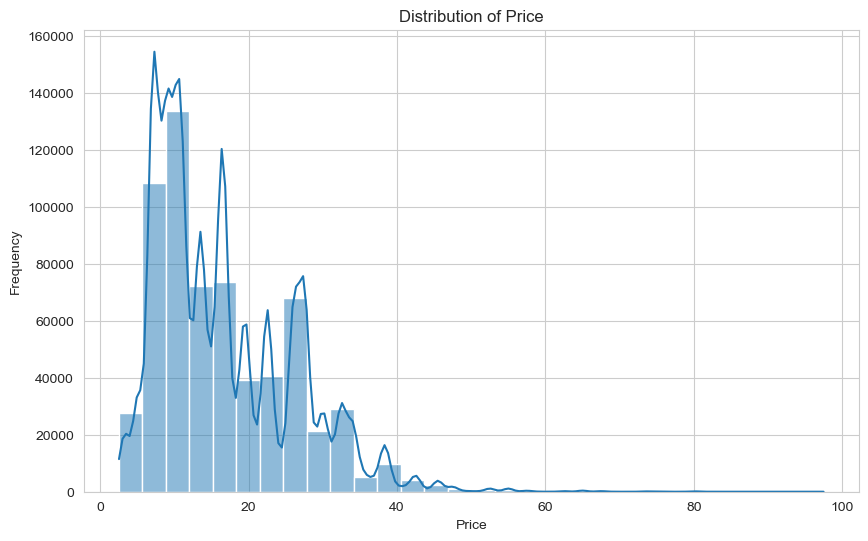

In [16]:
plt.figure(figsize=(10, 6))
sns.histplot(cab_rides["price"].dropna(), bins=30, kde=True)
plt.title("Distribution of Price")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

## 7. Distribution of Surge Multiplier
Plot a histogram to examine the distribution of surge multipliers.

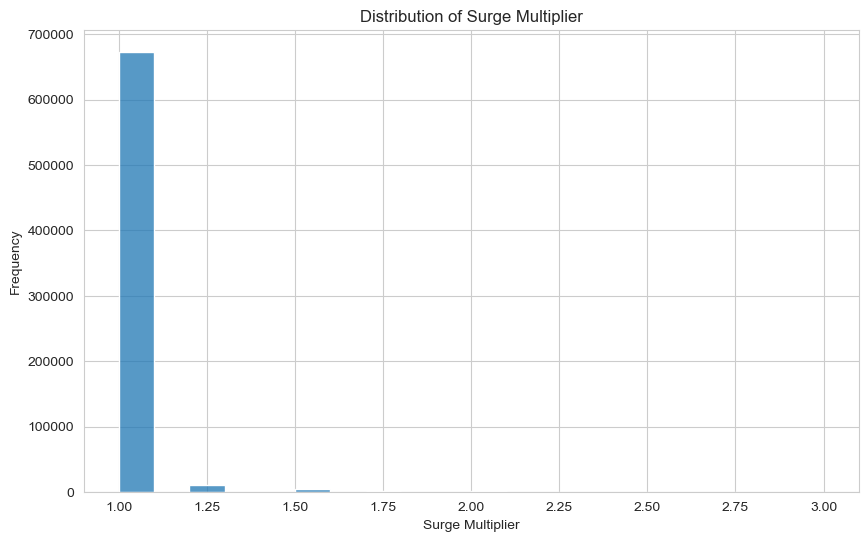

In [17]:
plt.figure(figsize=(10, 6))
sns.histplot(cab_rides["surge_multiplier"].dropna(), bins=20, kde=False)
plt.title("Distribution of Surge Multiplier")
plt.xlabel("Surge Multiplier")
plt.ylabel("Frequency")
plt.show()

## 8. Average Price by Hour of Day
Extract the hour from the ride timestamp and plot the average price by hour.

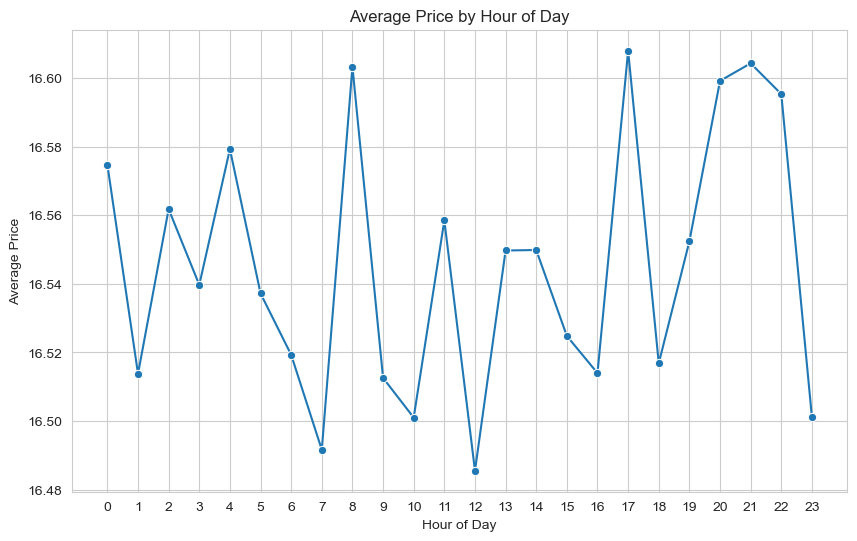

In [18]:
cab_rides["hour"] = cab_rides["time_stamp"].dt.hour

avg_price_by_hour = cab_rides.groupby("hour")["price"].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.lineplot(data=avg_price_by_hour, x="hour", y="price", marker="o")
plt.title("Average Price by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Price")
plt.xticks(range(0, 24))
plt.show()

## 9. Data Cleaning and Feature Engineering
Clean missing values, align timestamps for joining, merge ride and weather data, and create time-based features for downstream modeling.

### 9.1 Drop Rows with Missing Price
Remove ride records where `price` is null since price is the core target for surge pricing analysis.


In [19]:
cab_rides = cab_rides.dropna(subset=["price"]).copy()

print("Cab rides shape after dropping null prices:", cab_rides.shape)


Cab rides shape after dropping null prices: (637976, 11)


### 9.2 Fill Missing Rain Values
Replace missing values in the weather `rain` column with `0`.


In [21]:
weather["rain"] = weather["rain"].fillna(0)

print("Remaining nulls in weather['rain']:", weather["rain"].isnull().sum())


Remaining nulls in weather['rain']: 0


### 9.3 Round Timestamps to the Nearest Hour
Round `time_stamp` in both datasets to the nearest hour so they can be aligned during merging.


In [22]:
cab_rides["time_stamp_rounded"] = cab_rides["time_stamp"].dt.round("H")
weather["time_stamp_rounded"] = weather["time_stamp"].dt.round("H")

display(cab_rides[["time_stamp", "time_stamp_rounded"]].head())
display(weather[["time_stamp", "time_stamp_rounded"]].head())


C:\Users\spide\AppData\Local\Temp\ipykernel_48980\4077684992.py:1: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  cab_rides["time_stamp_rounded"] = cab_rides["time_stamp"].dt.round("H")
C:\Users\spide\AppData\Local\Temp\ipykernel_48980\4077684992.py:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  weather["time_stamp_rounded"] = weather["time_stamp"].dt.round("H")


,time_stamp,time_stamp_rounded
0,2018-12-16 09:30:07.890,2018-12-16 10:00:00
1,2018-11-27 02:00:23.677,2018-11-27 02:00:00
2,2018-11-28 01:00:22.198,2018-11-28 01:00:00
3,2018-11-30 04:53:02.749,2018-11-30 05:00:00
4,2018-11-29 03:49:20.223,2018-11-29 04:00:00


,time_stamp,time_stamp_rounded
0,2018-12-16 23:45:01,2018-12-17
1,2018-12-16 23:45:01,2018-12-17
2,2018-12-16 23:45:01,2018-12-17
3,2018-12-16 23:45:01,2018-12-17
4,2018-12-16 23:45:01,2018-12-17


### 9.4 Merge Cab Rides with Weather
Merge the cab rides data with weather data using rounded timestamp and location columns, keeping all ride records with a left join.


In [23]:
merged_df = pd.merge(
    cab_rides,
    weather,
    how="left",
    left_on=["time_stamp_rounded", "source"],
    right_on=["time_stamp_rounded", "location"]
)

print("Merged dataframe shape:", merged_df.shape)
display(merged_df.head())


Merged dataframe shape: (1176756, 20)


,distance,cab_type,time_stamp_x,destination,source,price,surge_multiplier,id,product_id,name,hour,time_stamp_rounded,temp,location,clouds,pressure,rain,time_stamp_y,humidity,wind
0,0.44,Lyft,2018-12-16 09:30:07.890,North Station,Haymarket Square,5.0,1.0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,lyft_line,Shared,9,2018-12-16 10:00:00,38.46,Haymarket Square,0.29,1022.25,0.0000,2018-12-16 09:45:01,0.76,7.68
1,0.44,Lyft,2018-11-27 02:00:23.677,North Station,Haymarket Square,11.0,1.0,4bd23055-6827-41c6-b23b-3c491f24e74d,lyft_premier,Lux,2,2018-11-27 02:00:00,44.31,Haymarket Square,1.00,1003.17,0.1123,2018-11-27 02:15:20,0.90,13.69
2,0.44,Lyft,2018-11-27 02:00:23.677,North Station,Haymarket Square,11.0,1.0,4bd23055-6827-41c6-b23b-3c491f24e74d,lyft_premier,Lux,2,2018-11-27 02:00:00,44.26,Haymarket Square,1.00,1004.48,0.7625,2018-11-27 01:45:22,0.90,13.40
3,0.44,Lyft,2018-11-28 01:00:22.198,North Station,Haymarket Square,7.0,1.0,981a3613-77af-4620-a42a-0c0866077d1e,lyft,Lyft,1,2018-11-28 01:00:00,38.87,Haymarket Square,0.11,992.27,0.0000,2018-11-28 00:45:22,0.75,9.33
4,0.44,Lyft,2018-11-30 04:53:02.749,North Station,Haymarket Square,26.0,1.0,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,lyft_luxsuv,Lux Black XL,4,2018-11-30 05:00:00,35.08,Haymarket Square,0.00,1013.71,0.0000,2018-11-30 04:52:54,0.70,5.25


### 9.5 Extract Time-Based Features
Create `hour`, `day_of_week`, and `month` from the ride timestamp for use in analysis and reinforcement learning features.


In [24]:
merged_df["hour"] = merged_df["time_stamp_x"].dt.hour
merged_df["day_of_week"] = merged_df["time_stamp_x"].dt.dayofweek
merged_df["month"] = merged_df["time_stamp_x"].dt.month

display(merged_df[["time_stamp_x", "hour", "day_of_week", "month"]].head())


,time_stamp_x,hour,day_of_week,month
0,2018-12-16 09:30:07.890,9,6,12
1,2018-11-27 02:00:23.677,2,1,11
2,2018-11-27 02:00:23.677,2,1,11
3,2018-11-28 01:00:22.198,1,2,11
4,2018-11-30 04:53:02.749,4,4,11


### 9.6 Inspect the Final Merged Dataset
Print the shape, preview the first five rows, and check how many null values remain after merging.


In [25]:
print("Final merged dataframe shape:", merged_df.shape)
display(merged_df.head())

print("Null values remaining after merge:")
display(merged_df.isnull().sum())


Final merged dataframe shape: (1176756, 22)


,distance,cab_type,time_stamp_x,destination,source,price,surge_multiplier,id,product_id,name,...,temp,location,clouds,pressure,rain,time_stamp_y,humidity,wind,day_of_week,month
0,0.44,Lyft,2018-12-16 09:30:07.890,North Station,Haymarket Square,5.0,1.0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,lyft_line,Shared,...,38.46,Haymarket Square,0.29,1022.25,0.0000,2018-12-16 09:45:01,0.76,7.68,6,12
1,0.44,Lyft,2018-11-27 02:00:23.677,North Station,Haymarket Square,11.0,1.0,4bd23055-6827-41c6-b23b-3c491f24e74d,lyft_premier,Lux,...,44.31,Haymarket Square,1.00,1003.17,0.1123,2018-11-27 02:15:20,0.90,13.69,1,11
2,0.44,Lyft,2018-11-27 02:00:23.677,North Station,Haymarket Square,11.0,1.0,4bd23055-6827-41c6-b23b-3c491f24e74d,lyft_premier,Lux,...,44.26,Haymarket Square,1.00,1004.48,0.7625,2018-11-27 01:45:22,0.90,13.40,1,11
3,0.44,Lyft,2018-11-28 01:00:22.198,North Station,Haymarket Square,7.0,1.0,981a3613-77af-4620-a42a-0c0866077d1e,lyft,Lyft,...,38.87,Haymarket Square,0.11,992.27,0.0000,2018-11-28 00:45:22,0.75,9.33,2,11
4,0.44,Lyft,2018-11-30 04:53:02.749,North Station,Haymarket Square,26.0,1.0,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,lyft_luxsuv,Lux Black XL,...,35.08,Haymarket Square,0.00,1013.71,0.0000,2018-11-30 04:52:54,0.70,5.25,4,11


Null values remaining after merge:


distance                0
cab_type                0
time_stamp_x            0
destination             0
source                  0
price                   0
surge_multiplier        0
id                      0
product_id              0
name                    0
hour                    0
time_stamp_rounded      0
temp                  984
location              984
clouds                984
pressure              984
rain                  984
time_stamp_y          984
humidity              984
wind                  984
day_of_week             0
month                   0
dtype: int64

## 10. Fix Duplicate Merges with Hourly Weather Aggregation
Aggregate weather records to one row per hour and location before merging so each cab ride matches at most one weather record.


### 10.1 Aggregate Weather by Hour and Location
Group the weather data by rounded timestamp and location, then take the mean of the numeric weather columns.


In [26]:
weather_hourly = (
    weather.groupby(["time_stamp_rounded", "location"], as_index=False)[
        ["temp", "clouds", "pressure", "rain", "humidity", "wind"]
    ]
    .mean()
)

print("Hourly weather shape:", weather_hourly.shape)
display(weather_hourly.head())


Hourly weather shape: (3972, 8)


,time_stamp_rounded,location,temp,clouds,pressure,rain,humidity,wind
0,2018-11-26 04:00:00,Back Bay,41.04,0.87,1014.39,0.0,0.92,1.46
1,2018-11-26 04:00:00,Beacon Hill,41.02,0.87,1014.39,0.0,0.92,1.50
2,2018-11-26 04:00:00,Boston University,41.07,0.86,1014.39,0.0,0.92,1.36
3,2018-11-26 04:00:00,Fenway,40.84,0.88,1014.35,0.0,0.93,1.31
4,2018-11-26 04:00:00,Financial District,40.95,0.89,1014.35,0.0,0.93,1.49


### 10.2 Redo the Merge Using Hourly Weather
Merge cab rides with the aggregated hourly weather data using a left join on rounded timestamp and location.


In [27]:
merged_df = pd.merge(
    cab_rides,
    weather_hourly,
    how="left",
    left_on=["time_stamp_rounded", "source"],
    right_on=["time_stamp_rounded", "location"]
)

print("Merged dataframe shape before dropping unmatched rows:", merged_df.shape)
display(merged_df.head())


Merged dataframe shape before dropping unmatched rows: (637976, 19)


,distance,cab_type,time_stamp,destination,source,price,surge_multiplier,id,product_id,name,hour,time_stamp_rounded,location,temp,clouds,pressure,rain,humidity,wind
0,0.44,Lyft,2018-12-16 09:30:07.890,North Station,Haymarket Square,5.0,1.0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,lyft_line,Shared,9,2018-12-16 10:00:00,Haymarket Square,38.4600,0.2900,1022.250,0.0000,0.7600,7.6800
1,0.44,Lyft,2018-11-27 02:00:23.677,North Station,Haymarket Square,11.0,1.0,4bd23055-6827-41c6-b23b-3c491f24e74d,lyft_premier,Lux,2,2018-11-27 02:00:00,Haymarket Square,44.2850,1.0000,1003.825,0.4374,0.9000,13.5450
2,0.44,Lyft,2018-11-28 01:00:22.198,North Station,Haymarket Square,7.0,1.0,981a3613-77af-4620-a42a-0c0866077d1e,lyft,Lyft,1,2018-11-28 01:00:00,Haymarket Square,38.8700,0.1100,992.270,0.0000,0.7500,9.3300
3,0.44,Lyft,2018-11-30 04:53:02.749,North Station,Haymarket Square,26.0,1.0,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,lyft_luxsuv,Lux Black XL,4,2018-11-30 05:00:00,Haymarket Square,35.0800,0.0000,1013.710,0.0000,0.7000,5.2500
4,0.44,Lyft,2018-11-29 03:49:20.223,North Station,Haymarket Square,9.0,1.0,e0126e1f-8ca9-4f2e-82b3-50505a09db9a,lyft_plus,Lyft XL,3,2018-11-29 04:00:00,Haymarket Square,37.6075,0.5375,998.540,0.0000,0.7075,10.0125


### 10.3 Drop Unmatched Rows
Remove rows where `temp` is null, which correspond to rides that did not find a matching weather record.


In [28]:
merged_df = merged_df.dropna(subset=["temp"]).copy()

print("Final merged dataframe shape:", merged_df.shape)


Final merged dataframe shape: (636992, 19)


### 10.4 Recreate Time-Based Features
Extract `hour`, `day_of_week`, and `month` from the ride timestamp after the corrected merge.


In [29]:
merged_df["hour"] = merged_df["time_stamp"].dt.hour
merged_df["day_of_week"] = merged_df["time_stamp"].dt.dayofweek
merged_df["month"] = merged_df["time_stamp"].dt.month

display(merged_df[["time_stamp", "hour", "day_of_week", "month"]].head())


,time_stamp,hour,day_of_week,month
0,2018-12-16 09:30:07.890,9,6,12
1,2018-11-27 02:00:23.677,2,1,11
2,2018-11-28 01:00:22.198,1,2,11
3,2018-11-30 04:53:02.749,4,4,11
4,2018-11-29 03:49:20.223,3,3,11


### 10.5 Validate the Final Dataset
Check the final shape and confirm that no null values remain.


In [30]:
print("Final merged dataframe shape:", merged_df.shape)
print("Expected shape is close to 637,976")

null_counts = merged_df.isnull().sum()
print("\nRemaining null values:")
display(null_counts)

print("Total remaining null values:", null_counts.sum())
print("Zero nulls remain:", null_counts.sum() == 0)


Final merged dataframe shape: (636992, 21)
Expected shape is close to 637,976

Remaining null values:


distance              0
cab_type              0
time_stamp            0
destination           0
source                0
price                 0
surge_multiplier      0
id                    0
product_id            0
name                  0
hour                  0
time_stamp_rounded    0
location              0
temp                  0
clouds                0
pressure              0
rain                  0
humidity              0
wind                  0
day_of_week           0
month                 0
dtype: int64

Total remaining null values: 0
Zero nulls remain: True
